# Loading and Preprocessing

This notebook covers the steps between the microscope and alignment: reading tilt series from the
common file formats, making sure the tilt angles are right, and preparing the projections. You will
learn:

* How `tomo.load` reads MRC, Digital Micrograph (DM) and HyperSpy files, single files or lists of
  files, and where it finds the tilt angles
* How to set or correct the tilt angles, and remove bad projections
* How to read SerialEM multi-frame data and average the frames
* Background removal, normalization, contrast inversion and filtering
* The log transform that makes bright-field data suitable for reconstruction
* Cropping and rebinning with HyperSpy, and saving

The example files are small test files from the `etspy/tests/test_data` folder of the
[ETSpy source repository](https://github.com/usnistgov/etspy). If you installed ETSpy from PyPI,
download that folder and set `data_dir` below to its location.

## Imports

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import hyperspy.api as hs

import etspy
import etspy.api as tomo
from etspy import datasets as ds
from etspy import utils

tomo.set_log_level("INFO")       # report where the tilts come from
data_dir = Path(etspy.__file__).parent / "tests" / "test_data"
sorted(p.name for p in data_dir.iterdir())

['Catalyst3DModel_TiltSeries180.hspy',
 'DM_Series_Test',
 'HAADF.ali',
 'HAADF.dm3',
 'HAADF.mrc',
 'HAADF.rawtlt',
 'HAADF.txt',
 'HAADF_Aligned.hspy',
 'SerialEM_MultiTilt_Test',
 'SerialEM_Multiframe_Test']

## Loading Files

### MRC Files

`tomo.load` returns a `TomoStack`. For MRC files, the tilt angles are read from the file header
when present (as written by SerialEM and FEI software), and otherwise from a `.rawtlt` file of the
same name, one angle per line. The log message says which was used.

In [2]:
stack = tomo.load(data_dir / "HAADF.mrc")
stack

INFO | ETSpy | Tilts found in MRC file header (etspy.io)


WARNING | ETSpy | The FEI extended header shows that the stored intensities are offset by -32768 from the acquired values (as when unsigned 16-bit counts are stored as signed integers), so 32768 was added to restore them. Use load(..., fei_offset_correction=False) to keep the stored values. (etspy.io)


<TomoStack, title: , dimensions: (77|256, 256)>

In [3]:
tilts = stack.tilts.data.squeeze()
print(f"{len(tilts)} tilts from {tilts.min()} to {tilts.max()} degrees")
stack.metadata.Tomography

77 tilts from -76.0 to 76.0 degrees


├── cropped = False
├── intensity_offset = 32768
├── tiltaxis = 0
├── xshift = 0
└── yshift = 0

FEI software stores unsigned detector counts as signed 16-bit integers with an offset of -32768.
ETSpy recognizes such files from their header and restores the original counts when loading
(`intensity_offset` in the metadata records the correction). Pass `fei_offset_correction=False`
to `tomo.load` to keep the stored values.

### Digital Micrograph Files

A DM file holding a whole tilt series is read in the same way, with the tilts taken from the
file's metadata. A series saved as one file per tilt is read by passing a list of files, in
acquisition order; the tilt of each file is read from its metadata:

In [4]:
dm_stack = tomo.load(data_dir / "HAADF.dm3")
print(dm_stack, dm_stack.tilts.data.squeeze()[:3])

dm_files = sorted((data_dir / "DM_Series_Test").glob("*.dm3"))
dm_series = tomo.load(dm_files)
print(dm_series, dm_series.tilts.data.squeeze())

<TomoStack, title: HAADF_Rebin16, dimensions: (91|64, 64)> [-90. -88. -86.]


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


  0%|          | 0/4 [00:00<?, ?it/s]

<TomoStack, title: DM_Series_Test, dimensions: (3|128, 128)> [-72.00303316 -69.0035991  -66.00416504]


### HyperSpy Files

A `TomoStack` saved with `save` (HyperSpy's HDF5 format, `.hspy`) is read back with its tilts,
shifts and metadata:

In [5]:
aligned = tomo.load(data_dir / "HAADF_Aligned.hspy")
aligned

<TomoStack, title: , dimensions: (77|256, 256)>

### Giving the Tilts Explicitly

When a file carries no tilt angles, or the angles in it are wrong, pass them to `tomo.load` with
`tilts=`; they take precedence over anything in the file. For a stack already loaded,
`set_tilts(start, increment)` sets evenly spaced angles, and the `tilts` attribute can also be
assigned an array directly:

In [6]:
fixed = tomo.load(data_dir / "HAADF.mrc", tilts=np.arange(-76, 78, 2.0))
print(fixed.tilts.data.squeeze()[:3])

fixed.set_tilts(-75.0, 2.0)
print(fixed.tilts.data.squeeze()[:3])

INFO | ETSpy | Tilts found in MRC file header (etspy.io)


INFO | ETSpy | Using user-provided tilts (etspy.io)


WARNING | ETSpy | The FEI extended header shows that the stored intensities are offset by -32768 from the acquired values (as when unsigned 16-bit counts are stored as signed integers), so 32768 was added to restore them. Use load(..., fei_offset_correction=False) to keep the stored values. (etspy.io)


[-76. -74. -72.]
[-75. -73. -71.]


### Removing Projections

Projections that are unusable (for example blurred by drift, or with the specimen out of view) can
be removed. Slicing the navigation axis with `inav` keeps a range; `remove_projections` removes any
list of indices. The tilts and shifts are kept in step with the data:

In [7]:
trimmed = stack.remove_projections([0, 1, 75, 76])
print(trimmed, trimmed.tilts.data.squeeze()[[0, -1]])
print(stack.inav[2:-2])

<TomoStack, title: , dimensions: (73|256, 256)> [-72.  72.]


<TomoStack, title: , dimensions: (73|256, 256)>


## SerialEM Multi-frame Data

SerialEM can record several short frames at each tilt instead of one long exposure; the frames are
then aligned to each other and averaged, which removes drift during the exposure. A list of MRC
files with their `.mdoc` files loads as a stack with two navigation axes (frames and tilts):

In [8]:
frame_files = sorted((data_dir / "SerialEM_Multiframe_Test").glob("*.mrc"))
frames = tomo.load(frame_files)
print(frames)
print("tilts of each frame:\n", frames.tilts.data)

INFO | ETSpy | Data appears to be a SerialEM multiframe series. (etspy.io)


INFO | ETSpy | SerialEM Multiframe stack successfully loaded. Use etspy.utils.register_serialem_stack to align frames. (etspy.io)


<TomoStack, title: Stack of , dimensions: (2, 3|1024, 1024)>
tilts of each frame:
 [[[-5.00151e+00]
  [-5.00151e+00]]

 [[-4.88000e-04]
  [-4.88000e-04]]

 [[ 5.00054e+00]
  [ 5.00054e+00]]]


`utils.register_serialem_stack` aligns the frames at each tilt to each other (with StackReg) and
averages them, giving an ordinary tilt series. With `ncpus` greater than one, tilts are processed
in parallel.

In [9]:
averaged = utils.register_serialem_stack(frames, show_progressbar=False)
print(averaged, averaged.tilts.data.squeeze())

<TomoStack, title: , dimensions: (3|1024, 1024)> [-5.00151e+00 -4.88000e-04  5.00054e+00]


## Preparing the Projections

The rest of the notebook uses the experimental needle dataset included with ETSpy.

In [10]:
needle = ds.get_needle_data()
needle.stats()

INFO | ETSpy | Tilts found in MRC file header (etspy.io)


WARNING | ETSpy | The FEI extended header shows that the stored intensities are offset by -32768 from the acquired values (as when unsigned 16-bit counts are stored as signed integers), so 32768 was added to restore them. Use load(..., fei_offset_correction=False) to keep the stored values. (etspy.io)


Mean: 5119.6
Std: 11485.53
Max: 65093.0
Min: 860.0



### Background Removal

The reconstruction assumes that each projection is proportional to the projected mass, so vacuum
must be zero. Dark-field (HAADF) detectors usually record an offset in vacuum, which reconstructs as
a ring of wrong intensity around the object. `remove_background` estimates it for each projection
and subtracts it:

* `"mode"` (default): the most common intensity, which is the vacuum level when vacuum fills a good
  part of the image
* `"border"`: the median of a strip of `border_width` pixels around the image edges
* a number, or an array with one value per projection

ETSpy warns before reconstructing data that still appear to have a background.

INFO | ETSpy | Removed background of 873 to 892 from the projections (etspy.base)


background removed from the first projections: [892. 890. 891. 891. 891.]


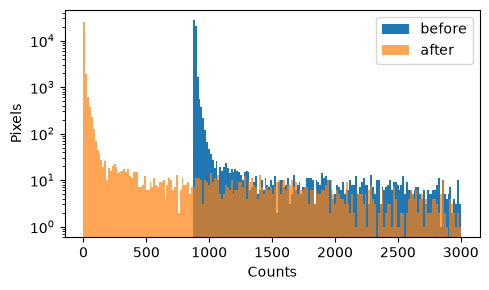

In [11]:
needle_bg = needle.remove_background()
print("background removed from the first projections:",
      needle_bg.metadata.Tomography.background[:5])

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(needle.data[30].ravel(), bins=200, range=(0, 3000), label="before")
ax.hist(needle_bg.data[30].ravel(), bins=200, range=(0, 3000), alpha=0.7, label="after")
ax.set(xlabel="Counts", ylabel="Pixels", yscale="log")
ax.legend()
fig.tight_layout()

### Normalization and Inversion

* `normalize(width)` rescales each projection independently: its minimum is subtracted and the
  result divided by mean + `width` x standard deviation. This evens out contrast changes along the
  series for display and alignment; it is not suitable before a quantitative reconstruction
* `invert()` reverses the contrast of each projection about the middle of its intensity range,
  which turns a bright-field image into a dark-field-like one for alignment methods that look for
  bright features

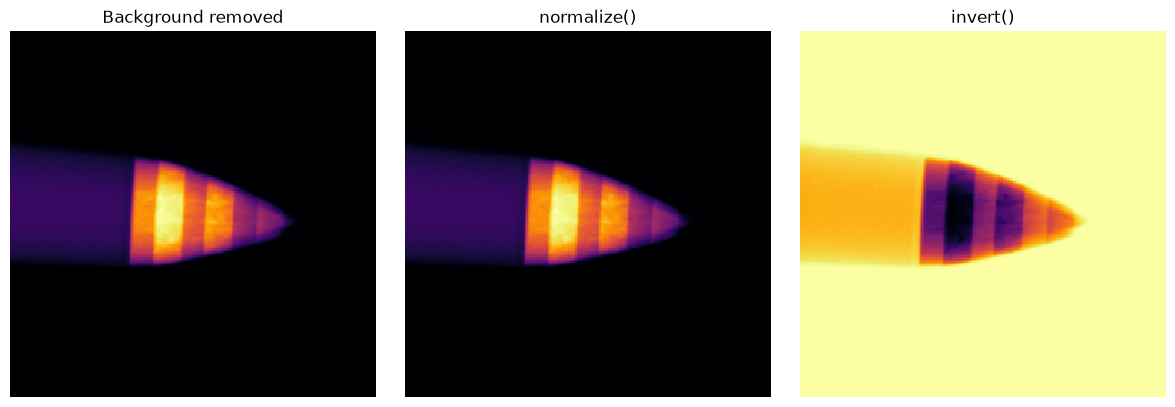

In [12]:
k = 38
hs.plot.plot_images(
    [needle_bg.inav[k], needle_bg.normalize().inav[k], needle_bg.invert().inav[k]],
    per_row=3, cmap="inferno", axes_decor="off", colorbar=None,
    label=["Background removed", "normalize()", "invert()"],
)
plt.gcf().set_size_inches(12, 4)
plt.tight_layout()

### Filtering

`filter` applies the same filter to every projection:

* `"median"`: removes isolated hot or dead pixels and shot noise spikes (neighbourhood `size`)
* `"bpf"`: a band-pass filter, which suppresses both noise and slow intensity variations; useful
  before alignment
* `"both"`: median then band-pass
* `"sobel"`: edge detection, sometimes useful for aligning objects with weak contrast

`taper` smoothly brings the image edges to the mean, which avoids artifacts in Fourier-based
alignment. Filtered copies are normally used to *measure* the alignment; the alignment is then
applied to the unfiltered data (see `align_other` in the
[alignment notebook](alignment_in_depth.ipynb)).

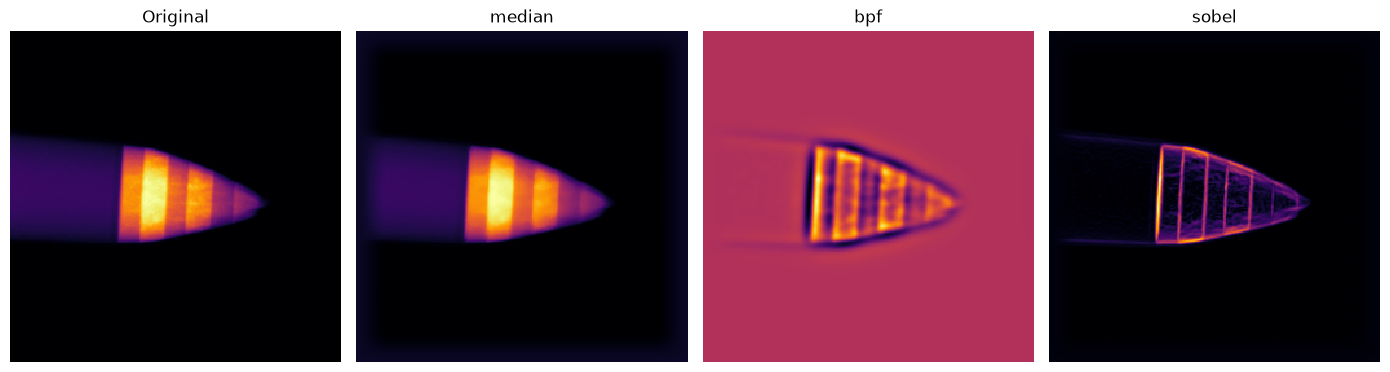

In [13]:
methods = ["median", "bpf", "sobel"]
hs.plot.plot_images(
    [needle_bg.inav[k]] + [needle_bg.filter(method=m).inav[k] for m in methods],
    per_row=4, cmap="inferno", axes_decor="off", colorbar=None,
    label=["Original"] + methods,
)
plt.gcf().set_size_inches(14, 4)
plt.tight_layout()

### Bright-field Data: the Log Transform

In a bright-field image vacuum is bright, the specimen is dark, and the transmitted intensity falls
roughly exponentially with the projected mass. Before reconstruction, bright-field data are
converted to absorbance, which is proportional to the projected mass:

absorbance = -ln((I - dark) / (i0 - dark))

where `i0` is the beam intensity in vacuum (estimated like the background: `"mode"`, `"border"`
or given) and `dark` is the detector's zero level. Vacuum then has an absorbance of zero, so no
background removal is needed afterwards.

To illustrate, we simulate a bright-field series from the needle data, with 1000 counts in vacuum
and shot noise, and convert it back. (Real bright-field contrast also includes diffraction and
phase contrast, so the absorbance is only approximately proportional to mass.)

INFO | ETSpy | Converted to absorbance using i0 of 988 to 991 and dark level of 0 to 0 (etspy.base)


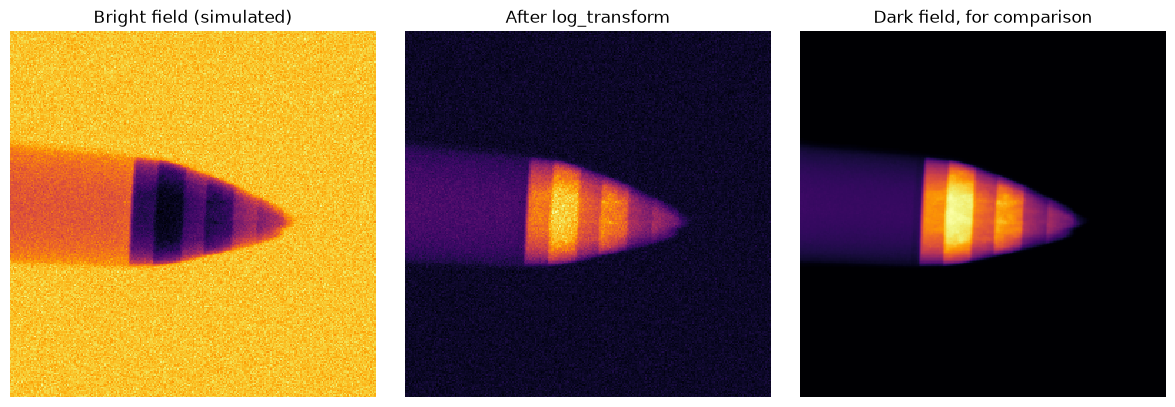

In [14]:
rng = np.random.default_rng(0)
mass = needle_bg.data.clip(0, None) / needle_bg.data.max()
bright_field = needle_bg.deepcopy()
bright_field.data = rng.poisson(1000 * np.exp(-1.5 * mass)).astype(np.float32)

absorbance = bright_field.log_transform(i0="mode")     # the log reports the i0 found

hs.plot.plot_images(
    [bright_field.inav[k], absorbance.inav[k], needle_bg.inav[k]],
    per_row=3, cmap="inferno", axes_decor="off", colorbar=None,
    label=["Bright field (simulated)", "After log_transform", "Dark field, for comparison"],
)
plt.gcf().set_size_inches(12, 4)
plt.tight_layout()

## Cropping, Rebinning and Data Types

A `TomoStack` is a HyperSpy `Signal2D`, so HyperSpy's tools work on it, and the tilts and shifts
follow:

* `isig[x0:x1, y0:y1]` crops the projections (x is along the tilt axis); `inav` selects
  projections
* `rebin(scale=[1, 2, 2])` bins by 2 in x and y (the first factor is for the tilt axis)
* `change_data_type("float32")` converts the data in place

In [15]:
small = needle_bg.isig[50:200, 20:240].rebin(scale=[1, 2, 2])
small.change_data_type("float32")
print(needle_bg, "->", small, small.data.dtype)

<TomoStack, title: , dimensions: (77|256, 256)> -> <TomoStack, title: , dimensions: (77|75, 110)> float32


## Saving

* `save` writes HyperSpy's HDF5 format (`.hspy`), which keeps the tilts, shifts and metadata, and
  is read back by `tomo.load`
* `save_raw` writes the data as a raw binary file with the shape and data type in its name, for
  other software
* HyperSpy can also write MRC and TIFF files: `save("name.mrc")`, `save("name.tif")`

In [16]:
small.save("needle_prepared.hspy", overwrite=True)
print(small.save_raw("needle_prepared"))
print(tomo.load("needle_prepared.hspy"))

needle_prepared_77x110x75_float32.rpl


<TomoStack, title: , dimensions: (77|75, 110)>


## Next Steps

The prepared series is now ready to be aligned: see the [alignment notebook](alignment_in_depth.ipynb)
and the [main demo](etspy_demo.ipynb).